# Gender analysis based on weight and height

Sklearn can be very useful for data analysis in Python/Jupyter

## Information obtained from Kaggle

#### Project done by Miguel Estrada

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import numpy as np
# Import SMOTE
from imblearn.over_sampling import SMOTE

In [2]:
#Importing the data
data_measures = pd.read_csv('weight-height.csv')
data_measures.head(2)

,Gender,Height,Weight
0,Male,73.847017,241.893563
1,Male,68.781904,162.310473


<Axes: xlabel='Height', ylabel='Weight'>

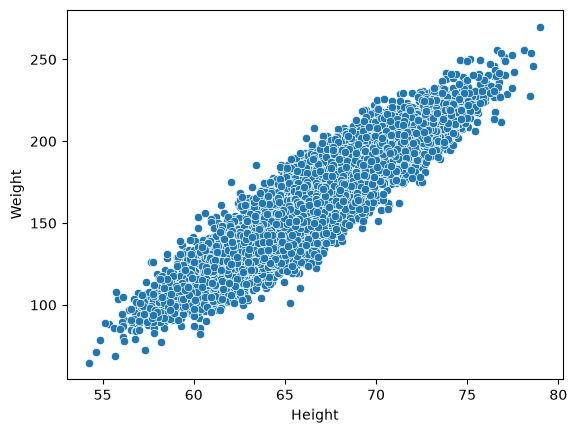

In [3]:
sns.scatterplot(data=data_measures, y='Weight', x='Height')

array([[<Axes: title={'center': 'Height'}>,
        <Axes: title={'center': 'Weight'}>]], dtype=object)

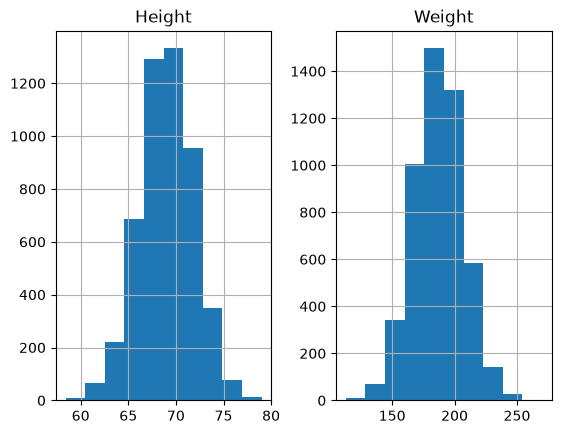

In [4]:
males = data_measures[data_measures['Gender'] == 'Male']
females = data_measures[data_measures['Gender'] == 'Female']
males.hist()

array([[<Axes: title={'center': 'Height'}>,
        <Axes: title={'center': 'Weight'}>]], dtype=object)

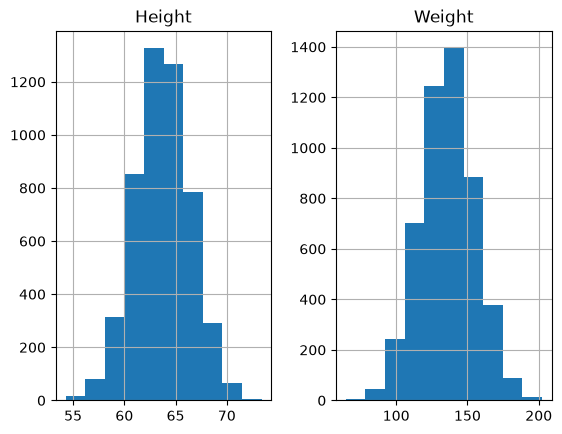

In [5]:
females.hist()

In [6]:
data_measures.isna().sum()

Gender    0
Height    0
Weight    0
dtype: int64

In [7]:
data_measures.describe()

,Height,Weight
count,10000.000000,10000.000000
mean,66.367560,161.440357
std,3.847528,32.108439
min,54.263133,64.700127
25%,63.505620,135.818051
50%,66.318070,161.212928
75%,69.174262,187.169525
max,78.998742,269.989699


In [8]:
data_measures['Gender'].value_counts()

Gender
Male      5000
Female    5000
Name: count, dtype: int64

<Axes: xlabel='Height', ylabel='Weight'>

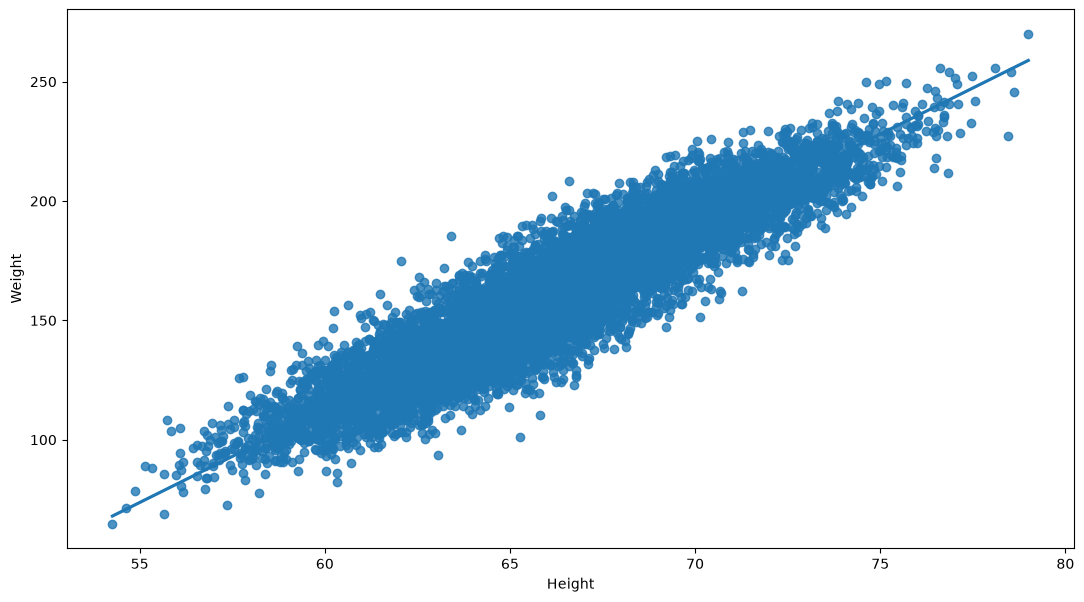

In [9]:
plt.figure(figsize=(13, 7))
sns.regplot(data=data_measures, y='Weight', x='Height')

In [10]:
from sklearn.preprocessing import LabelEncoder
labelencoder = LabelEncoder()
data_measures_2 = data_measures
data_measures_2['Gender'] = labelencoder.fit_transform(data_measures_2['Gender'])
data_measures_2.corr()

,Gender,Height,Weight
Gender,1.000000,0.691072,0.796723
Height,0.691072,1.000000,0.924756
Weight,0.796723,0.924756,1.000000


# Analysis with all the variables
Trying to predict the gender which height and weight as data

In [11]:
X = data_measures.drop('Gender', axis=1)
Y = data_measures['Gender']

from sklearn.preprocessing import LabelEncoder
labelencoder = LabelEncoder()
Y = labelencoder.fit_transform(Y.values)

In [12]:
x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.2)

In [13]:
sc = StandardScaler()
x_train = sc.fit_transform(x_train)
x_test = sc.transform(x_test)

In [14]:
smote = SMOTE()
x_train_smote, y_train_smote = smote.fit_resample(x_train, y_train)

classifier = LogisticRegression(fit_intercept=True)
classifier.fit(x_train_smote, y_train_smote)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

## Logistic Regression: coefficients and feature importance

The model coefficients show how each standardized variable affects the log-odds of predicting the positive class. Because `Height` and `Weight` are standardized using the training data, their coefficient magnitudes can be compared directly.

- **Coefficient:** direction and strength of the relationship with the positive class.
- **Odds ratio:** `exp(coefficient)`, the multiplicative change in the odds for a one-standard-deviation increase in that variable.
- **Relative importance:** each variable's absolute coefficient divided by the sum of absolute coefficients. This is a coefficient-based comparison, not a causal measure.

In [15]:
# Get the feature names and logistic regression coefficients
feature_names = X.columns

coefficient_values = classifier.coef_[0]

# Build a table with coefficients and odds ratios
coefficient_analysis = pd.DataFrame({
    'Variable': feature_names,
    'Coefficient': coefficient_values,
    'Absolute Coefficient': np.abs(coefficient_values),
    'Odds Ratio (per 1 SD)': np.exp(coefficient_values)
})

# Calculate each variable's relative importance
coefficient_analysis['Relative Importance (%)'] = (
    coefficient_analysis['Absolute Coefficient']
    / coefficient_analysis['Absolute Coefficient'].sum()
) * 100

# Sort variables from most to least important
coefficient_analysis = coefficient_analysis.sort_values(
    by='Absolute Coefficient',
    ascending=False
).reset_index(drop=True)

coefficient_analysis

,Variable,Coefficient,Absolute Coefficient,Odds Ratio (per 1 SD),Relative Importance (%)
0,Weight,5.991735,5.991735,400.108163,77.946192
1,Height,-1.695279,1.695279,0.183548,22.053808


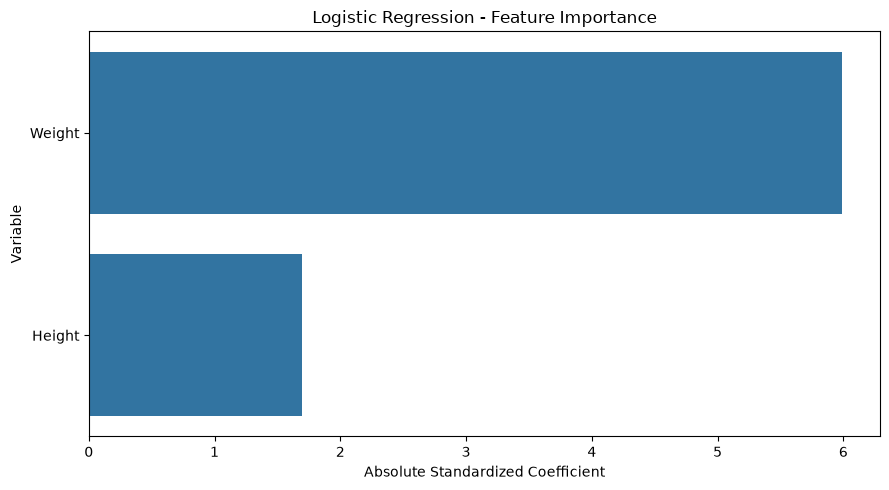

In [16]:
# Visualize coefficient-based feature importance
plt.figure(figsize=(9, 5))

sns.barplot(
    data=coefficient_analysis,
    x='Absolute Coefficient',
    y='Variable'
)

plt.title('Logistic Regression - Feature Importance')
plt.xlabel('Absolute Standardized Coefficient')
plt.ylabel('Variable')
plt.tight_layout()
plt.show()

### How to interpret the coefficients

A positive coefficient means that increasing the variable raises the model's log-odds of predicting the positive class (`classifier.classes_[1]`). A negative coefficient lowers those log-odds.

The odds ratio is interpreted per one-standard-deviation increase in the variable:
- An odds ratio greater than 1 increases the odds of the positive class.
- An odds ratio below 1 decreases the odds of the positive class.
- An odds ratio close to 1 indicates a smaller effect.

The relative-importance percentage compares the absolute coefficient magnitudes. It does not indicate causation, and it should be interpreted alongside model performance and the data distribution.

**Positive class:** `classifier.classes_[1]` (the class label encoded as 1).

In [17]:
# Show the original gender label associated with each encoded class
gender_label_map = {0: 'Female', 1: 'Male'}

class_labels = pd.DataFrame({
    'Encoded Class': classifier.classes_,
    'Gender Label': [gender_label_map[class_value] for class_value in classifier.classes_]
})

class_labels

,Encoded Class,Gender Label
0,0,Female
1,1,Male


In [18]:
predictions = classifier.predict(x_test)

<Axes: >

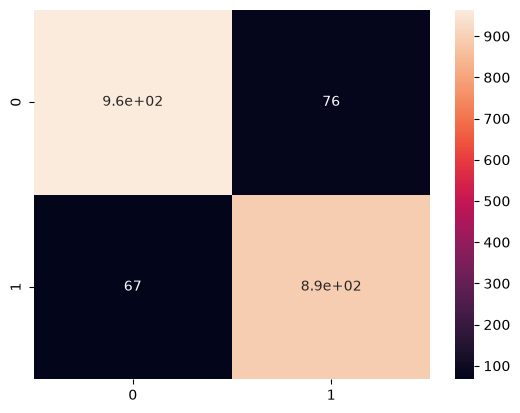

In [19]:
cm = confusion_matrix(y_test, predictions)
sns.heatmap(cm, annot=True)

In [20]:
## Accuracy of the model
accuracy_score(y_test, predictions)

0.9285

In [21]:
from sklearn.metrics import classification_report
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

           0       0.94      0.93      0.93      1040
           1       0.92      0.93      0.93       960

    accuracy                           0.93      2000
   macro avg       0.93      0.93      0.93      2000
weighted avg       0.93      0.93      0.93      2000



In [22]:
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

mean_squared_error_ = mean_squared_error(y_test, predictions)
r2_score_ = r2_score(y_test, predictions)
mean_absolute_error_ = mean_absolute_error(y_test, predictions)

print("Mean Squared Error: {}".format(mean_squared_error_))
print("R2 score: {}".format(r2_score_))
print("Mean Absolute Error: {}".format(mean_absolute_error_))

Mean Squared Error: 0.0715
R2 score: 0.7135416666666667
Mean Absolute Error: 0.0715
